# 4 - Regressão logística: a diferença entre gêneros persiste? (H1)

**Projeto final — SME0828 Introdução à Ciência de Dados**
Prof. Francisco A. Rodrigues — ICMC/USP

Grupo: _(nomes)_

<hr>

Na análise descritiva vimos que mulheres têm **mais pedidos negados** que homens. Mas isso pode acontecer simplesmente porque, em média, elas têm **perfis de risco diferentes** (por exemplo, renda menor).

Para separar o efeito do gênero do efeito do risco, usamos a **regressão logística** com **variáveis de controle**: comparamos homens e mulheres **com a mesma renda, o mesmo DTI, o mesmo LTV e o mesmo tipo de empréstimo**.

**Hipótese H1:** depois desses controles, o gênero ainda está associado à probabilidade de negação.
- H0: o coeficiente de `mulher` é igual a zero (sem diferença);
- rejeitamos H0 se p < 0,05.

### Relembrando: odds ratio

A regressão logística modela o **logaritmo das chances** (log-odds) como uma combinação linear das variáveis:

$$\ln\left(\frac{p}{1-p}\right) = \beta_0 + \beta_1\,\text{mulher} + \beta_2\,\text{log(renda)} + \dots$$

O valor $e^{\beta_1}$ é a **odds ratio (OR)** do gênero:
- OR = 1: mesmas chances de negação para homens e mulheres;
- OR > 1: mulheres têm **mais** chances de negação;
- OR < 1: mulheres têm **menos** chances de negação.

Também reportamos o efeito em **pontos percentuais (p.p.)**, que é mais fácil de interpretar: "ser mulher muda a probabilidade de negação em X p.p."

### 1. Bibliotecas

Além das bibliotecas usuais, usamos o `pyfixest`. Ele ajusta a regressão logística com **efeitos fixos** (explicados na seção 4), o que seria inviável com o `scikit-learn` ou o `statsmodels`: seriam mais de 2.400 variáveis *dummy* de instituição em 1,5 milhão de linhas.

In [1]:
import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# Define sementes aleatórias para reprodutibilidade.
SEMENTE = 42
random.seed(SEMENTE)
np.random.seed(SEMENTE)

# Paleta usada nos gráficos (a mesma das aulas).
BLUE   = "#2a78d6"   # homens / modelo
ORANGE = "#eb6834"   # mulheres
GRAY   = "#898781"   # referência

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)
os.makedirs("../figuras", exist_ok=True)
os.makedirs("../resultados", exist_ok=True)

import pyfixest as pf

### 2. Leitura e preparação dos dados

Usamos a **base principal** (casos completos de renda, DTI e LTV), gerada no notebook `02_amostra`. Antes de ajustar os modelos, ainda precisamos tratar três pontos (registrados no `docs/protocolo.md`, seção 7):

1. **Renda menor ou igual a zero**: vamos usar o logaritmo da renda, que não existe para valores ≤ 0. Essas linhas são removidas.
2. **Outliers do LTV**: há valores impossíveis (até 29 milhões de %). Em vez de remover, **limitamos** o LTV aos percentis 0,1% e 99,9% (*winsorização*): valores acima do limite passam a valer o limite.
3. **Estado e idade faltantes**: removemos essas linhas para que todas as especificações usem a mesma amostra.

In [2]:
colunas = ["lei", "state_code", "income", "combined_loan_to_value_ratio",
           "loan_type", "dti", "applicant_age", "negado", "mulher"]

data = pd.read_parquet("../data/amostra_principal.parquet", columns=colunas)
print("Dimensão inicial:", data.shape)

# 1. Renda <= 0
print("Linhas com renda <= 0:", (data["income"] <= 0).sum())
data = data[data["income"] > 0]

# 2. Winsorização do LTV
limite_inf, limite_sup = data["combined_loan_to_value_ratio"].quantile([0.001, 0.999])
print(f"Limites do LTV: [{limite_inf:.2f}, {limite_sup:.2f}]")
data["ltv"] = data["combined_loan_to_value_ratio"].clip(limite_inf, limite_sup)

# Logaritmo da renda
data["log_renda"] = np.log(data["income"])

# 3. Estado e idade faltantes
data = data.dropna(subset=["state_code", "applicant_age"]).reset_index(drop=True)
print("Dimensão final:", data.shape)
data.head()

Dimensão inicial: (1547246, 9)
Linhas com renda <= 0: 7111
Limites do LTV: [13.99, 115.52]


Dimensão final: (1532885, 11)


,lei,state_code,income,combined_loan_to_value_ratio,loan_type,dti,applicant_age,negado,mulher,ltv,log_renda
0,549300QFJDBOCX7WKY08,TX,65.0,97.000,1,36%-<50%,25-34,0,0,97.000,4.174387
1,549300HW662MN1WU8550,CA,178.0,80.000,1,36%-<50%,35-44,0,1,80.000,5.181784
2,549300HW662MN1WU8550,CA,61.0,96.500,2,50%-60%,<25,0,0,96.500,4.110874
3,549300HW662MN1WU8550,MN,69.0,97.000,1,20%-<30%,25-34,0,1,97.000,4.234107
4,549300D36J5CQX0I4F44,MI,59.0,98.189,2,20%-<30%,<25,0,0,98.189,4.077537


### 3. Variáveis categóricas: one-hot encoding

DTI, tipo de empréstimo e faixa etária são categóricas. Assim como na aula de preparação de dados, usamos `pd.get_dummies(..., drop_first=True)`: cada categoria vira uma coluna 0/1, e a **primeira categoria é removida** para servir de **referência**.

As referências escolhidas são: DTI `<20%`, tipo de empréstimo 1 (convencional) e idade `25-34`. Os nomes das categorias são simplificados para poderem ser usados nas fórmulas.

In [3]:
nomes_dti = {"<20%": "ate20", "20%-<30%": "20a30", "30%-<36%": "30a36",
             "36%-<50%": "36a50", "50%-60%": "50a60", ">60%": "acima60"}
nomes_idade = {"25-34": "25a34", "<25": "menos25", "35-44": "35a44", "45-54": "45a54",
               "55-64": "55a64", "65-74": "65a74", ">74": "acima74"}

# Categóricas com a referência na primeira posição
data["dti"] = pd.Categorical(data["dti"].astype(str).map(nomes_dti), categories=list(nomes_dti.values()))
data["idade"] = pd.Categorical(data["applicant_age"].map(nomes_idade), categories=list(nomes_idade.values()))
data["tipo"] = pd.Categorical(data["loan_type"], categories=["1", "2", "3", "4"])

dummies = pd.get_dummies(data[["dti", "tipo", "idade"]], drop_first=True).astype(int)
data = pd.concat([data, dummies], axis=1)

controles_dti = [c for c in dummies.columns if c.startswith("dti_")]
controles_tipo = [c for c in dummies.columns if c.startswith("tipo_")]
controles_idade = [c for c in dummies.columns if c.startswith("idade_")]

print("Dummies criadas:", list(dummies.columns))

Dummies criadas: ['dti_20a30', 'dti_30a36', 'dti_36a50', 'dti_50a60', 'dti_acima60', 'tipo_2', 'tipo_3', 'tipo_4', 'idade_menos25', 'idade_35a44', 'idade_45a54', 'idade_55a64', 'idade_65a74', 'idade_acima74']


### 4. Especificações do modelo

Ajustamos o modelo várias vezes, adicionando controles aos poucos. Assim vemos **como a diferença entre gêneros muda** à medida que comparamos perfis cada vez mais parecidos:

| Especificação | Variáveis |
|---|---|
| (1) | só `mulher` (diferença bruta) |
| (2) | + renda, LTV, DTI e tipo de empréstimo |
| (3) | + efeito fixo de **estado** |
| (4) | (2) + efeito fixo de **instituição** |
| (5) **[H1]** | (2) + efeitos fixos de instituição **e** estado |
| E1 (exploratória) | (5) + faixa etária |

**Efeito fixo** é equivalente a incluir uma *dummy* para cada estado (ou instituição). Na prática, isso faz o modelo comparar homens e mulheres **dentro do mesmo estado** e **dentro do mesmo banco**. Assim, diferenças entre bancos (alguns negam mais que outros) não se confundem com o efeito do gênero.

**Erros-padrão clusterizados por instituição:** pedidos do mesmo banco não são independentes (seguem as mesmas regras internas). Os erros-padrão "clusterizados" levam isso em conta e evitam intervalos de confiança estreitos demais.

Na sintaxe do `pyfixest`, os efeitos fixos vêm depois da barra `|`.

In [4]:
controles = " + ".join(["log_renda", "ltv"] + controles_dti + controles_tipo)
idade = " + ".join(controles_idade)

especificacoes = [
    ("(1) Só gênero",                       "negado ~ mulher"),
    ("(2) + controles",                     f"negado ~ mulher + {controles}"),
    ("(3) + EF estado",                     f"negado ~ mulher + {controles} | state_code"),
    ("(4) + EF instituição",                f"negado ~ mulher + {controles} | lei"),
    ("(5) + EF instituição e estado [H1]",  f"negado ~ mulher + {controles} | lei + state_code"),
    ("E1: (5) + faixa etária",              f"negado ~ mulher + {controles} + {idade} | lei + state_code"),
]

print(especificacoes[4][1])

negado ~ mulher + log_renda + ltv + dti_20a30 + dti_30a36 + dti_36a50 + dti_50a60 + dti_acima60 + tipo_2 + tipo_3 + tipo_4 | lei + state_code


### 5. Ajuste dos modelos

Para cada especificação, ajustamos:
- a **regressão logística** (`pf.feglm`, família `logit`), da qual tiramos a odds ratio do gênero;
- um **modelo linear de probabilidade** (`pf.feols`), com as mesmas variáveis, cujo coeficiente já é o efeito em **pontos percentuais**. Ele serve como verificação e é muito próximo do efeito marginal médio do logit (diferença ≤ 0,05 p.p.).

O ajuste das especificações com efeitos fixos leva alguns minutos.

In [5]:
resultados = []

for nome, formula in especificacoes:
    logit = pf.feglm(formula, data=data, family="logit", vcov={"CRV1": "lei"})
    linear = pf.feols(formula, data=data, vcov={"CRV1": "lei"})

    b = logit.coef()["mulher"]
    ic_inf, ic_sup = logit.confint().loc["mulher"]
    pp_inf, pp_sup = linear.confint().loc["mulher"]

    resultados.append({
        "Especificação": nome,
        "N": logit._N,
        "OR": np.exp(b),
        "OR IC inf": np.exp(ic_inf),
        "OR IC sup": np.exp(ic_sup),
        "p-valor": logit.pvalue()["mulher"],
        "Efeito (p.p.)": 100 * linear.coef()["mulher"],
        "p.p. IC inf": 100 * pp_inf,
        "p.p. IC sup": 100 * pp_sup,
    })
    print(f"{nome}: OR = {np.exp(b):.3f}  p = {logit.pvalue()['mulher']:.3f}")

tabela = pd.DataFrame(resultados)
tabela.round(3)

(1) Só gênero: OR = 1.160  p = 0.000


(2) + controles: OR = 1.022  p = 0.205


(3) + EF estado: OR = 1.010  p = 0.561


(4) + EF instituição: OR = 1.015  p = 0.264


(5) + EF instituição e estado [H1]: OR = 1.005  p = 0.678


E1: (5) + faixa etária: OR = 0.974  p = 0.050


,Especificação,N,OR,OR IC inf,OR IC sup,p-valor,Efeito (p.p.),p.p. IC inf,p.p. IC sup
0,(1) Só gênero,1532885,1.160,1.098,1.225,0.000,1.409,0.776,2.041
1,(2) + controles,1532885,1.022,0.988,1.057,0.205,0.197,-0.075,0.468
2,(3) + EF estado,1532885,1.010,0.976,1.045,0.561,0.123,-0.154,0.400
3,(4) + EF instituição,1514115,1.015,0.989,1.041,0.264,0.080,-0.100,0.260
4,(5) + EF instituição e estado [H1],1514115,1.005,0.980,1.032,0.678,0.026,-0.154,0.207
5,E1: (5) + faixa etária,1514115,0.974,0.948,1.000,0.050,-0.203,-0.393,-0.013


### 6. Resultados

O gráfico mostra a **odds ratio do gênero** em cada especificação, com o intervalo de confiança de 95%. A linha cinza (OR = 1) indica **nenhuma diferença** entre homens e mulheres. Se o intervalo cruza essa linha, a diferença **não é estatisticamente significativa**.

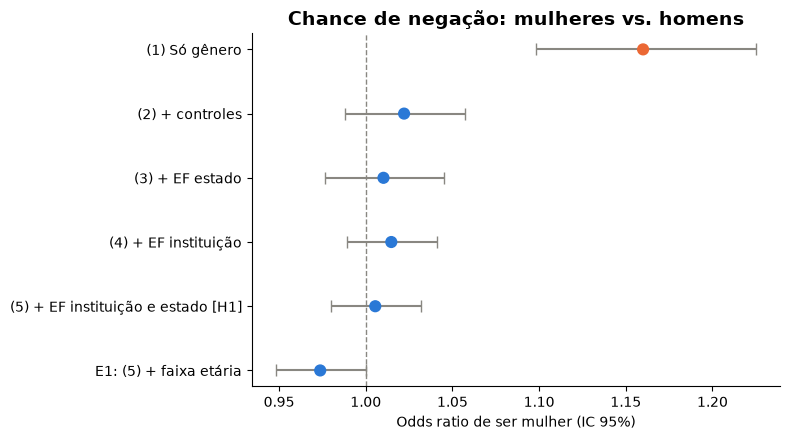

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(len(tabela))[::-1]
cores = [ORANGE if p < 0.05 else BLUE for p in tabela["p-valor"]]

ax.errorbar(tabela["OR"], y,
            xerr=[tabela["OR"] - tabela["OR IC inf"], tabela["OR IC sup"] - tabela["OR"]],
            fmt="none", ecolor=GRAY, capsize=4)
ax.scatter(tabela["OR"], y, color=cores, s=60, zorder=3)
ax.axvline(1, color=GRAY, linestyle="--", linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels(tabela["Especificação"])
ax.set_xlabel("Odds ratio de ser mulher (IC 95%)")
ax.set_title("Chance de negação: mulheres vs. homens", fontsize=14, fontweight="bold")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.savefig("../figuras/h1_odds_ratio.png", dpi=150)
plt.show()

Vamos também olhar os coeficientes dos **controles** na especificação principal (5). Eles mostram como cada fator de risco se relaciona com a negação, e servem para conferir se o modelo faz sentido (por exemplo, DTI maior deveria aumentar a chance de negação).

In [7]:
modelo_h1 = pf.feglm(especificacoes[4][1], data=data, family="logit", vcov={"CRV1": "lei"})

coeficientes = pd.DataFrame({
    "coeficiente": modelo_h1.coef(),
    "odds_ratio": np.exp(modelo_h1.coef()),
    "p-valor": modelo_h1.pvalue(),
})
coeficientes.round(3)

,coeficiente,odds_ratio,p-valor
Coefficient,,,
mulher,0.005,1.005,0.678
log_renda,-0.419,0.657,0.000
ltv,0.017,1.017,0.000
dti_20a30,-0.677,0.508,0.000
dti_30a36,-0.795,0.451,0.000
dti_36a50,-0.741,0.477,0.000
dti_50a60,0.569,1.766,0.000
dti_acima60,3.875,48.169,0.000
tipo_2,-0.152,0.859,0.052


### 7. Salvando os resultados

In [8]:
tabela_md = tabela.copy()
tabela_md["OR (IC 95%)"] = tabela.apply(lambda r: f"{r['OR']:.3f} ({r['OR IC inf']:.3f}; {r['OR IC sup']:.3f})", axis=1)
tabela_md["Efeito em p.p. (IC 95%)"] = tabela.apply(lambda r: f"{r['Efeito (p.p.)']:.2f} ({r['p.p. IC inf']:.2f}; {r['p.p. IC sup']:.2f})", axis=1)
tabela_md["p-valor"] = tabela["p-valor"].map(lambda p: "<0,001" if p < 0.001 else f"{p:.3f}")
tabela_md = tabela_md[["Especificação", "N", "OR (IC 95%)", "p-valor", "Efeito em p.p. (IC 95%)"]]

with open("../resultados/h1_especificacoes.md", "w", encoding="utf-8") as f:
    f.write(tabela_md.to_markdown(index=False))
    f.write("\n\nOR > 1: maior chance de negação para mulheres. Erros-padrão clusterizados por instituição. "
            "Efeito em p.p. pelo modelo linear de probabilidade. E1 é exploratória.\n")

tabela_md

,Especificação,N,OR (IC 95%),p-valor,Efeito em p.p. (IC 95%)
0,(1) Só gênero,1532885,1.160 (1.098; 1.225),"<0,001",1.41 (0.78; 2.04)
1,(2) + controles,1532885,1.022 (0.988; 1.057),0.205,0.20 (-0.07; 0.47)
2,(3) + EF estado,1532885,1.010 (0.976; 1.045),0.561,0.12 (-0.15; 0.40)
3,(4) + EF instituição,1514115,1.015 (0.989; 1.041),0.264,0.08 (-0.10; 0.26)
4,(5) + EF instituição e estado [H1],1514115,1.005 (0.980; 1.032),0.678,0.03 (-0.15; 0.21)
5,E1: (5) + faixa etária,1514115,0.974 (0.948; 1.000),0.050,-0.20 (-0.39; -0.01)


### Conclusão

- **Sem controles** (especificação 1), mulheres têm **16% mais chances** de ter o pedido negado (OR = 1,16; p < 0,001), o que corresponde a **1,4 p.p.** a mais na probabilidade de negação.
- Ao incluir **renda, LTV, DTI e tipo de empréstimo** (especificação 2), a diferença cai para OR = 1,02 e **deixa de ser significativa** (p = 0,21).
- Na especificação principal **(5)**, comparando homens e mulheres **com o mesmo perfil de risco, no mesmo estado e no mesmo banco**, a odds ratio é **1,005** (IC 95%: 0,980 a 1,032; p = 0,68), um efeito de apenas **0,03 p.p.**
- **Não rejeitamos H0**: com os controles disponíveis, **não há evidência** de que o gênero esteja associado à negação. A diferença bruta é explicada pelas diferenças de perfil de risco (principalmente renda e DTI).
- Os controles se comportam como esperado: renda maior **reduz** a chance de negação (OR = 0,66 por unidade de log), e DTI acima de 60% a **multiplica por 48** em relação a DTI abaixo de 20%.
- Na análise exploratória **E1** (com faixa etária), a OR fica em 0,974 (p = 0,050): no limite da significância e na direção **oposta** (mulheres com chance ligeiramente **menor**). Por ser exploratória e marginal, não muda a conclusão.

**Limitação importante:** o HMDA público não tem **credit score** nem histórico de crédito. Se esses fatores diferirem entre homens e mulheres, o resultado pode mudar. Associação estatística também não é prova de (ausência de) discriminação.